In [4]:
#Library imports for the project.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import Reweighing
from aif360.algorithms.inprocessing import PrejudiceRemover
from aif360.algorithms.postprocessing import EqOddsPostprocessing

C:\Users\dango\AppData\Local\Programs\Python\Python313\Lib\site-packages\inFairness\utils\ndcg.py:37: FutureWarning: We've integrated functorch into PyTorch. As the final step of the integration, `functorch.vmap` is deprecated as of PyTorch 2.0 and will be deleted in a future version of PyTorch >= 2.3. Please use `torch.vmap` instead; see the PyTorch 2.0 release notes and/or the `torch.func` migration guide for more details https://pytorch.org/docs/main/func.migrating.html
  vect_normalized_discounted_cumulative_gain = vmap(
C:\Users\dango\AppData\Local\Programs\Python\Python313\Lib\site-packages\inFairness\utils\ndcg.py:48: FutureWarning: We've integrated functorch into PyTorch. As the final step of the integration, `functorch.vmap` is deprecated as of PyTorch 2.0 and will be deleted in a future version of PyTorch >= 2.3. Please use `torch.vmap` instead; see the PyTorch 2.0 release notes and/or the `torch.func` migration guide for more details https://pytorch.org/docs/main/func.migrat

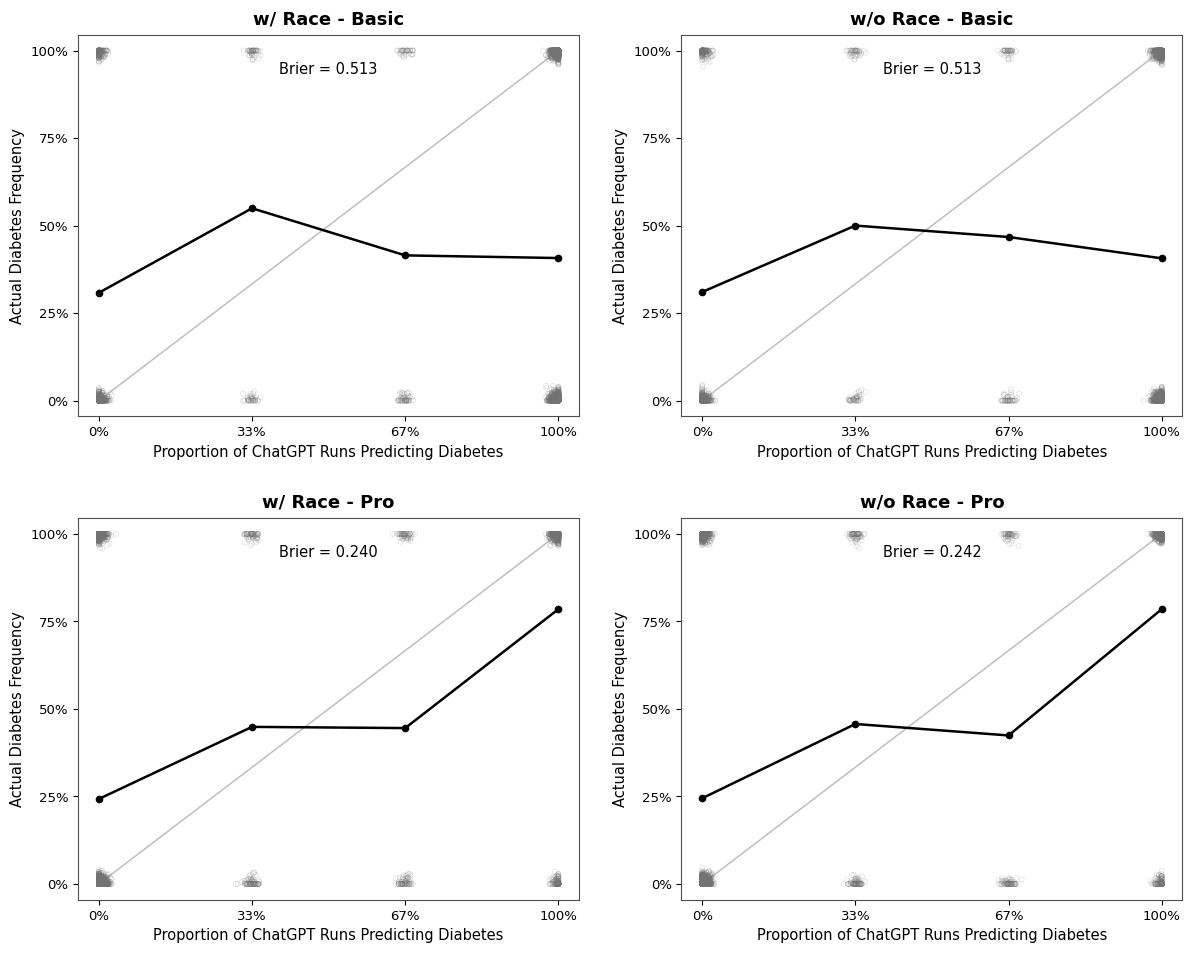

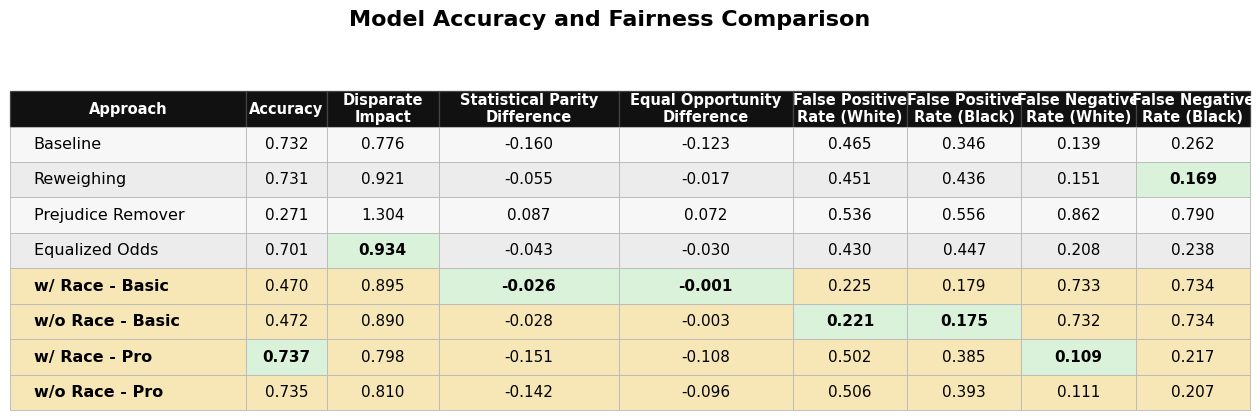

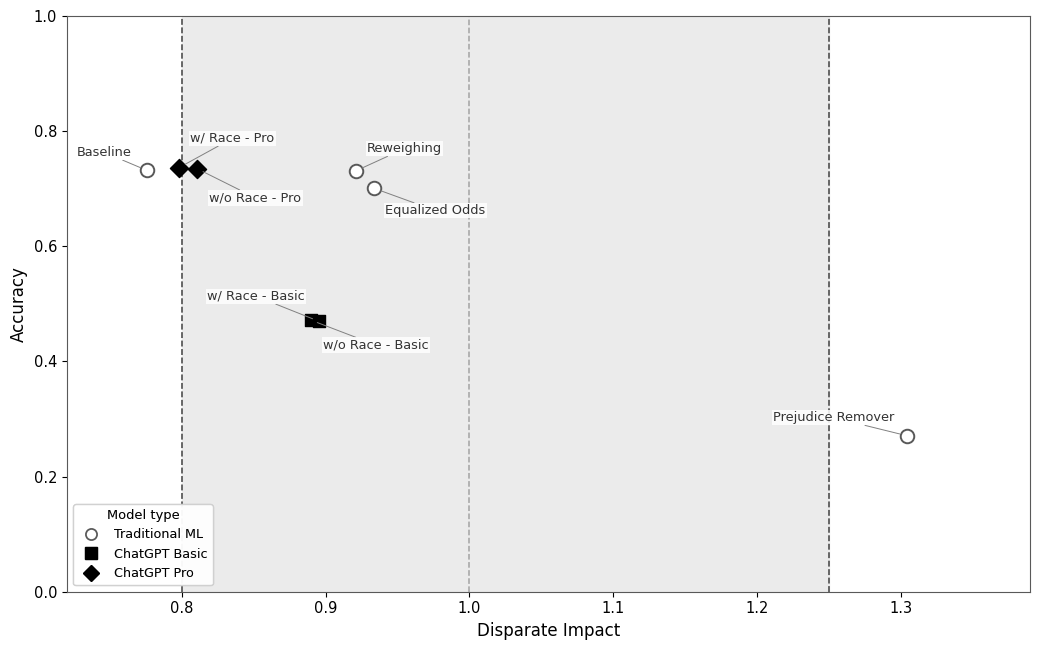

In [7]:
#Settings and inputs.
BASE_DIR = Path(r"")

FILES = {"w/ Race - Basic": BASE_DIR / "diabetes_race_basic.csv", "w/o Race - Basic": BASE_DIR / "diabetes_no_race_basic.csv",
         "w/ Race - Pro": BASE_DIR / "diabetes_race_pro.csv", "w/o Race - Pro": BASE_DIR / "diabetes_no_race_pro.csv",}

OUT = BASE_DIR / "outputs"
OUT.mkdir(parents = True, exist_ok = True)

VOTE_COLS = ["pred_label_1", "pred_label_2", "pred_label_3"]

LLM_ORDER = list(FILES)

ML_ORDER = ["Baseline", "Reweighing", "Prejudice Remover", "Equalized Odds"]

APPROACH_ORDER = ML_ORDER + LLM_ORDER

#Loading, validating, and aligning records across the CSV files.
raw = {}

for name, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"CSV not found for {name}: {path}")

    d = pd.read_csv(path)

    required = {"race", "true_label", "pred_label", *VOTE_COLS}

    if not required.issubset(d.columns):
        raise ValueError(f"{name} is missing: {sorted(required - set(d.columns))}")

    d = d.loc[d["race"].isin(["Caucasian", "AfricanAmerican"])].copy()

    d.reset_index(drop = True, inplace = True)

    for column in ["true_label", "pred_label", *VOTE_COLS]:

        d[column] = pd.to_numeric(d[column], errors = "raise")

        if (d[column].isna().any()or not d[column].isin([0, 1]).all()):
            raise ValueError(
                f"{name}: {column} must contain only 0 and 1, without missing values")

        d[column] = d[column].astype(int)

    #Fraction of votes predicting diabetes (label 1).
    #0 votes for diabetes = 0.000
    #1 vote for diabetes = 0.333
    #2 votes for diabetes = 0.667
    #3 votes for diabetes = 1.000

    d["diabetes_vote_fraction"] = d[VOTE_COLS].mean(axis = 1)
    raw[name] = d


#Align patient records across all four files.

id_options = ["encounter_id", "record_id", "case_id", "row_id", "patient_id", "id"]

id_col = next((c for c in id_options
               if all(c in d.columns and d[c].notna().all() and d[c].is_unique for d in raw.values())), None)

ref_name = "w/o Race - Pro"

if id_col is not None:

    for name in raw:
        raw[name][id_col] = raw[name][id_col].astype(str)

    shared_ids = set.intersection(*(set(d[id_col]) for d in raw.values()))

    if not shared_ids:
        raise ValueError(f"No common records across the four files using {id_col}")

    reference = raw[ref_name].loc[raw[ref_name][id_col].isin(shared_ids)].copy()

    reference.reset_index(drop=True, inplace=True)

    aligned = {name: (d.set_index(id_col, drop=False).loc[reference[id_col]].reset_index(drop = True)) for name, d in raw.items()}

else:
    if len(set(map(len, raw.values()))) != 1:
        raise ValueError("The four files have different row counts and no shared unique record ID")

    shared_columns = set.intersection(*(set(d.columns) for d in raw.values()))

    ignored_columns = {"pred_label", *VOTE_COLS, "diabetes_vote_fraction", "race_binary", "pred_prob", "predicted_probability", "probability",
        "diabetes_probability", "prob_diabetes", "diabetes_risk", "risk_score", "response", "llm_response", "chatgpt_response", "prompt",
        "explanation", "confidence"}

    check_cols = sorted(c for c in shared_columns if c not in ignored_columns and not c.startswith(("pred_", "llm_", "chatgpt_", "Unnamed:")))

    if (not {"race", "true_label"}.issubset(check_cols) or len(check_cols) < 3):
        raise ValueError("Cannot confirm identical row order. Add a unique record ID to each CSV")

    reference = raw[ref_name].reset_index(drop = True)

    for name, d in raw.items():
        if not d[check_cols].equals(reference[check_cols]):
            raise ValueError(f"Row order / clinical attributes are not aligned for {name}")

    aligned = {name: d.reset_index(drop = True) for name, d in raw.items()}


for name, d in aligned.items():

    if not d[["race", "true_label"]].equals(reference[["race", "true_label"]]):
        raise ValueError(f"Race/true_label records do not match in {name}")


#Defining the held-out test set.
y_all = reference["true_label"].to_numpy(dtype = int)

race_all = (reference["race"] == "AfricanAmerican").astype(int).to_numpy()

strata = (reference["race"].astype(str) + "_" + reference["true_label"].astype(str))

train_idx, test_idx = train_test_split(np.arange(len(reference)),test_size = 0.30, random_state = 42, stratify = strata)

y_train = y_all[train_idx]
y_test = y_all[test_idx]

race_train = race_all[train_idx]
race_test = race_all[test_idx]

N_TEST = len(test_idx)


#Preparing features.
#exclude true labels, ChatGPT outputs, prompts, and IDs.
#retain race through race_binary for the traditional ML models.

exclude = {"race", "race_binary", "true_label", "pred_label", *VOTE_COLS, "diabetes_vote_fraction", "pred_prob", "predicted_probability", "probability",
    "diabetes_probability", "prob_diabetes", "diabetes_risk", "risk_score", "response", "llm_response", "chatgpt_response", "prompt", "explanation",
    "confidence", "encounter_id", "patient_nbr", "patient_id", "record_id", "case_id", "row_id", "id", "index"}

feature_cols = [c for c in reference.columns if c not in exclude and not c.startswith(("pred_", "llm_", "chatgpt_", "Unnamed:"))]

if not feature_cols:
    raise ValueError("No clinical features remain for traditional ML training")

X = pd.get_dummies(reference[feature_cols],drop_first = True,dummy_na = True)

X.insert(0, "race_binary", race_all)

X = X.astype(float).replace(
    [np.inf, -np.inf], np.nan
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

# Impute using training-set statistics only.
training_medians = X_train.median()

X_train = X_train.fillna(training_medians).fillna(0)
X_test = X_test.fillna(training_medians).fillna(0)


def to_aif(Xframe, labels):

    data = Xframe.reset_index(drop=True).copy()
    data["true_label"] = np.asarray(labels, dtype=int)

    return BinaryLabelDataset(
        favorable_label=0,
        unfavorable_label=1,
        df=data,
        label_names=["true_label"],
        protected_attribute_names=["race_binary"],
        privileged_protected_attributes=[[0]],
        unprivileged_protected_attributes=[[1]]
    )


ds_train = to_aif(X_train, y_train)
ds_test = to_aif(X_test, y_test)

privileged = [{"race_binary": 0}]
unprivileged = [{"race_binary": 1}]

predictions = {}


# ============================================================
# 4. TRAIN TRADITIONAL MACHINE LEARNING APPROACHES
# ============================================================

# BASELINE LOGISTIC REGRESSION

scaler = StandardScaler()

tr_s = scaler.fit_transform(X_train)
te_s = scaler.transform(X_test)

base = LogisticRegression(
    max_iter=2000,
    random_state=42
)

base.fit(tr_s, y_train)

predictions["Baseline"] = base.predict(te_s).astype(int)


# REWEIGHING

rw = Reweighing(
    unprivileged_groups=unprivileged,
    privileged_groups=privileged
)

train_rw = rw.fit_transform(ds_train)

scaler_rw = StandardScaler()

tr_rw = scaler_rw.fit_transform(train_rw.features)
te_rw = scaler_rw.transform(ds_test.features)

model_rw = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model_rw.fit(
    tr_rw,
    train_rw.labels.ravel(),
    sample_weight=train_rw.instance_weights.ravel()
)

predictions["Reweighing"] = model_rw.predict(
    te_rw
).astype(int)


# PREJUDICE REMOVER

pr = PrejudiceRemover(
    sensitive_attr="race_binary",
    eta=25.0
)

pr.fit(ds_train)

predictions["Prejudice Remover"] = (
    pr.predict(ds_test).labels.ravel().astype(int)
)


# EQUALIZED ODDS

# Fit the postprocessor on a separate validation set.

sub_idx, val_idx = train_test_split(
    np.arange(len(y_train)),
    test_size=0.20,
    random_state=42,
    stratify=(
        pd.Series(race_train).astype(str)
        + "_"
        + pd.Series(y_train).astype(str)
    )
)

sub_ds = ds_train.subset(sub_idx)
val_ds = ds_train.subset(val_idx)

scaler_eo = StandardScaler()

tr_eo = scaler_eo.fit_transform(sub_ds.features)
val_eo = scaler_eo.transform(val_ds.features)
te_eo = scaler_eo.transform(ds_test.features)

eo_base = LogisticRegression(
    max_iter=2000,
    random_state=42
)

eo_base.fit(
    tr_eo,
    sub_ds.labels.ravel()
)

val_prediction = val_ds.copy()

val_prediction.labels = eo_base.predict(
    val_eo
).reshape(-1, 1)

eo = EqOddsPostprocessing(
    unprivileged_groups=unprivileged,
    privileged_groups=privileged,
    seed=42
)

eo.fit(val_ds, val_prediction)

test_prediction = ds_test.copy()

test_prediction.labels = eo_base.predict(
    te_eo
).reshape(-1, 1)

predictions["Equalized Odds"] = (
    eo.predict(test_prediction)
      .labels.ravel()
      .astype(int)
)


# ============================================================
# 5. ADD ALL FOUR CHATGPT MAJORITY-VOTE PREDICTIONS
# ============================================================

for name in LLM_ORDER:

    predictions[name] = (
        aligned[name]
        .iloc[test_idx]["pred_label"]
        .to_numpy(dtype=int)
    )


# ============================================================
# 6. CALCULATE ALL METRICS ON THE SAME TEST PATIENTS
# ============================================================

# Preserve original AIF360 convention:
#
# Favorable / positive class = NO DIABETES (label 0).
#
# DI = P(predicted 0 | Black) / P(predicted 0 | White)
#
# SPD = P(predicted 0 | Black) - P(predicted 0 | White)
#
# EOD = TPR(Black) - TPR(White), for favorable class 0.
#
# Consequently:
# FPR = P(predicted 0 | actually diabetes)
# FNR = P(predicted 1 | actually no diabetes)
#
# These differ from the usual clinical convention in which
# a diabetes diagnosis is the positive class.


def rate(values, mask):

    return (
        float(np.mean(values[mask]))
        if np.any(mask)
        else np.nan
    )


def evaluate(name, yp):

    yp = np.asarray(yp, dtype=int)

    white = race_test == 0
    black = race_test == 1

    p0_white = rate(yp == 0, white)
    p0_black = rate(yp == 0, black)

    tpr_white = rate(
        yp == 0,
        white & (y_test == 0)
    )

    tpr_black = rate(
        yp == 0,
        black & (y_test == 0)
    )

    return {
        "Approach": name,

        "Accuracy": accuracy_score(y_test, yp),

        "Disparate Impact": (
            p0_black / p0_white
            if p0_white > 0
            else np.nan
        ),

        "Statistical Parity Difference": (
            p0_black - p0_white
        ),

        "Equal Opportunity Difference": (
            tpr_black - tpr_white
        ),

        "False Positive Rate (White)": rate(
            yp == 0,
            white & (y_test == 1)
        ),

        "False Positive Rate (Black)": rate(
            yp == 0,
            black & (y_test == 1)
        ),

        "False Negative Rate (White)": rate(
            yp == 1,
            white & (y_test == 0)
        ),

        "False Negative Rate (Black)": rate(
            yp == 1,
            black & (y_test == 0)
        )
    }


results = pd.DataFrame([
    evaluate(name, predictions[name])
    for name in APPROACH_ORDER
])

results.to_csv(
    OUT / "model_comparison.csv",
    index=False
)


# ============================================================
# OUTPUT 1: FOUR BRIER / RELIABILITY PLOTS
# ============================================================

# Vote fraction =
# (pred_label_1 + pred_label_2 + pred_label_3) / 3
#
# Possible values: 0, 1/3, 2/3, 1.
#
# These are ensemble-vote fractions rather than
# independently calibrated diabetes probabilities.

fig, axes = plt.subplots(
    2, 2,
    figsize=(12.4, 10),
    sharex=False,
    sharey=False
)

rng = np.random.default_rng(42)

for ax, name in zip(axes.flat, LLM_ORDER):

    d = aligned[name].iloc[test_idx]

    frac = d[
        "diabetes_vote_fraction"
    ].to_numpy(dtype=float)

    votes = d[VOTE_COLS].sum(
        axis=1
    ).to_numpy(dtype=int)

    # Brier score based on three-vote fractions.
    brier = brier_score_loss(y_test, frac)

    # Empirical diabetes frequency at each possible vote count.
    xs = []
    ys = []

    for k in range(4):

        mask = votes == k

        if np.any(mask):
            xs.append(k / 3)
            ys.append(float(y_test[mask].mean()))

    # Perfect calibration reference.
    ax.plot(
        [0, 1],
        [0, 1],
        color="0.75",
        linewidth=1.1,
        zorder=1
    )

    # Patient-level points with minimal jitter.
    ax.scatter(
        np.clip(
            frac + rng.normal(0, 0.009, len(frac)),
            0, 1
        ),

        np.clip(
            y_test + rng.normal(0, 0.013, len(y_test)),
            0, 1
        ),

        s=13,
        facecolors="none",
        edgecolors="0.45",
        linewidths=0.45,
        alpha=0.25,
        rasterized=True,
        zorder=2
    )

    # Actual observed calibration curve.
    ax.plot(
        xs,
        ys,
        "-o",
        color="black",
        linewidth=1.8,
        markersize=4.5,
        zorder=3
    )

    ax.set_title(
        name,
        fontsize=13,
        weight="bold",
        pad=8
    )

    ax.text(
        0.5,
        0.91,
        f"Brier = {brier:.3f}",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=10.5
    )

    ax.set_xlim(-0.045, 1.045)
    ax.set_ylim(-0.045, 1.045)

    # Show all four discrete voting percentages on every panel.
    ax.set_xticks([0, 1/3, 2/3, 1])

    ax.set_xticklabels([
        "0%",
        "33%",
        "67%",
        "100%"
    ])

    ax.set_yticks([
        0,
        0.25,
        0.50,
        0.75,
        1
    ])

    ax.yaxis.set_major_formatter(
        PercentFormatter(1)
    )

    ax.set_xlabel(
        "Proportion of ChatGPT Runs Predicting Diabetes",
        fontsize=10.5
    )

    ax.set_ylabel(
        "Actual Diabetes Frequency",
        fontsize=10.5
    )

    ax.tick_params(
        axis="both",
        labelbottom=True,
        labelsize=9.5
    )

    for spine in ax.spines.values():
        spine.set_color("0.3")

    ax.grid(False)

fig.tight_layout(pad=2.4)

fig.savefig(
    OUT / "brier_four_panel.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()


table_df = results.copy()

# Order rows exactly how you want them displayed
row_order = [
    "Baseline",
    "Reweighing",
    "Prejudice Remover",
    "Equalized Odds",
    "w/ Race - Basic",
    "w/o Race - Basic",
    "w/ Race - Pro",
    "w/o Race - Pro"
]

table_df["Approach"] = pd.Categorical(
    table_df["Approach"],
    categories=row_order,
    ordered=True
)
table_df = table_df.sort_values("Approach").reset_index(drop=True)

# Round values for display
display_df = table_df.copy()
for col in display_df.columns:
    if col != "Approach":
        display_df[col] = display_df[col].map(lambda x: f"{x:.3f}")

# More compact poster-friendly labels
display_df = display_df.rename(columns={
    "Approach": "Approach",
    "Accuracy": "Accuracy",
    "Disparate Impact": "Disparate\nImpact",
    "Statistical Parity Difference": "Statistical Parity\nDifference",
    "Equal Opportunity Difference": "Equal Opportunity\nDifference",
    "False Positive Rate (White)": "False Positive\nRate (White)",
    "False Positive Rate (Black)": "False Positive\nRate (Black)",
    "False Negative Rate (White)": "False Negative\nRate (White)",
    "False Negative Rate (Black)": "False Negative\nRate (Black)"
})

# Keep numeric version for deciding what to highlight
numeric_df = table_df.copy()

# Identify "best" values to bold
# Accuracy: highest is best
best_accuracy_idx = numeric_df["Accuracy"].idxmax()

# Disparate Impact: closest to 1 is best
best_di_idx = (numeric_df["Disparate Impact"] - 1).abs().idxmin()

# For fairness difference metrics, closest to 0 is best
best_spd_idx = numeric_df["Statistical Parity Difference"].abs().idxmin()
best_eod_idx = numeric_df["Equal Opportunity Difference"].abs().idxmin()
best_fpr_w_idx = numeric_df["False Positive Rate (White)"].abs().idxmin()
best_fpr_b_idx = numeric_df["False Positive Rate (Black)"].abs().idxmin()
best_fnr_w_idx = numeric_df["False Negative Rate (White)"].abs().idxmin()
best_fnr_b_idx = numeric_df["False Negative Rate (Black)"].abs().idxmin()

best_map = {
    "Accuracy": best_accuracy_idx,
    "Disparate\nImpact": best_di_idx,
    "Statistical Parity\nDifference": best_spd_idx,
    "Equal Opportunity\nDifference": best_eod_idx,
    "False Positive\nRate (White)": best_fpr_w_idx,
    "False Positive\nRate (Black)": best_fpr_b_idx,
    "False Negative\nRate (White)": best_fnr_w_idx,
    "False Negative\nRate (Black)": best_fnr_b_idx
}

# Build the table figure
fig, ax = plt.subplots(figsize=(16, 4.6))
ax.axis("off")

# Table data
cell_text = display_df.values.tolist()
col_labels = display_df.columns.tolist()

# Column widths tuned for poster use
col_widths = [
    0.19,   # Approach
    0.065,  # Accuracy
    0.09,   # DI
    0.145,  # SPD
    0.14,   # EOD
    0.092,  # FPR W
    0.092,  # FPR B
    0.092,  # FNR W
    0.092   # FNR B
]

tbl = ax.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc="center",
    colLoc="center",
    colWidths=col_widths,
    bbox=[0.0, 0.0, 1.0, 0.90]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.5)

# Theme colors
header_bg = "#111111"      # black
header_fg = "white"
row_alt_1 = "#F7F7F7"
row_alt_2 = "#ECECEC"
llm_row_bg = "#F7E7B6"     # light gold
edge_color = "#B8B8B8"
best_bg = "#D9F2D9"        # pale green

# Style cells
n_rows = len(display_df)
n_cols = len(display_df.columns)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor(edge_color)
    cell.set_linewidth(0.6)

    # Header row
    if row == 0:
        cell.set_facecolor(header_bg)
        cell.get_text().set_color(header_fg)
        cell.get_text().set_fontweight("bold")
        cell.get_text().set_fontsize(10.5)
        cell.set_edgecolor("#444444")
        cell.set_linewidth(0.9)

    else:
        approach_name = display_df.iloc[row - 1, 0]

        # Highlight ChatGPT rows in light gold
        if "Basic" in approach_name or "Pro" in approach_name:
            cell.set_facecolor(llm_row_bg)
        else:
            cell.set_facecolor(row_alt_1 if row % 2 == 1 else row_alt_2)

        # Left-align the approach names
        if col == 0:
            cell.get_text().set_ha("left")
            cell.get_text().set_fontsize(11.5)

# Bold + highlight the best value in each metric column
for j, col_name in enumerate(display_df.columns):
    if col_name == "Approach":
        continue
    best_row = best_map[col_name] + 1  # +1 because table header is row 0
    cell = tbl[(best_row, j)]
    cell.get_text().set_fontweight("bold")
    cell.set_facecolor(best_bg)

# Add subtle emphasis to ChatGPT rows' approach names
for i in range(1, n_rows + 1):
    approach_name = display_df.iloc[i - 1, 0]
    if "Basic" in approach_name or "Pro" in approach_name:
        tbl[(i, 0)].get_text().set_fontweight("bold")

# Save high-resolution version
plt.savefig(
    OUT / "model_comparison_table.png",
    dpi=500,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ============================================================
# OUTPUT 3: ACCURACY VS DISPARATE IMPACT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10.5, 6.6)
)

# Shade the disparate impact reference interval.
ax.axvspan(
    0.8,
    1.25,
    color="0.92",
    zorder=0
)

# Reference boundaries.
ax.axvline(
    0.8,
    color="0.28",
    linestyle="--",
    linewidth=1.15,
    zorder=1
)

ax.axvline(
    1.25,
    color="0.28",
    linestyle="--",
    linewidth=1.15,
    zorder=1
)

# Equal selection-rate reference.
ax.axvline(
    1.0,
    color="0.64",
    linestyle="--",
    linewidth=1.1,
    zorder=1
)


# Plot all eight approaches.
for _, r in results.iterrows():

    name = r["Approach"]
    di = r["Disparate Impact"]
    acc = r["Accuracy"]

    if name in ML_ORDER:

        ax.scatter(
            di,
            acc,
            s=95,
            marker="o",
            facecolor="white",
            edgecolor="0.35",
            linewidth=1.4,
            zorder=4
        )

    elif "Basic" in name:

        ax.scatter(
            di,
            acc,
            s=85,
            marker="s",
            facecolor="black",
            edgecolor="black",
            zorder=5
        )

    else:

        ax.scatter(
            di,
            acc,
            s=85,
            marker="D",
            facecolor="black",
            edgecolor="black",
            zorder=5
        )


# Position labels near their corresponding markers.
# Values are (horizontal offset, vertical offset, alignment).
# Offsets are in points, relative to the actual marker.

label_positions = {
    "Baseline": (-11, 13, "right"),
    "Reweighing": (8, 16, "left"),
    "Prejudice Remover": (-9, 13, "right"),
    "Equalized Odds": (8, -16, "left"),
    "w/ Race - Basic": (-10, 18, "right"),
    "w/o Race - Basic": (9, -18, "left"),
    "w/ Race - Pro": (8, 21, "left"),
    "w/o Race - Pro": (9, -21, "left"),
}

for _, r in results.iterrows():

    name = r["Approach"]

    dx, dy, ha = label_positions[name]

    ax.annotate(
        name,

        xy=(
            r["Disparate Impact"],
            r["Accuracy"]
        ),

        xytext=(dx, dy),
        textcoords="offset points",

        ha=ha,
        va="center",
        fontsize=9.3,
        color="0.20",

        arrowprops=dict(
            arrowstyle="-",
            linewidth=0.7,
            color="0.50",
            shrinkA=0,
            shrinkB=5
        ),

        bbox=dict(
            boxstyle="square,pad=0.1",
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        ),

        annotation_clip=False,
        zorder=6
    )


valid_di = (results["Disparate Impact"].replace([np.inf, -np.inf], np.nan).dropna())

ax.set_xlim(min(0.72, valid_di.min() - 0.05),max(1.39, valid_di.max() + 0.07))

ax.set_ylim(0, 1.0)

ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.set_xlabel("Disparate Impact",fontsize=12)

ax.set_ylabel("Accuracy", fontsize = 12)

ax.tick_params(labelsize = 10.5)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_color("0.35")

model_keys = [

    Line2D(
        [], [],
        marker="o",
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="0.35",
        markeredgewidth=1.25,
        markersize=8,
        label="Traditional ML"
    ),

    Line2D(
        [], [],
        marker="s",
        linestyle="none",
        markerfacecolor="black",
        markeredgecolor="black",
        markersize=8,
        label="ChatGPT Basic"
    ),

    Line2D([], [], marker = "D", linestyle = "none", markerfacecolor = "black", markeredgecolor = "black", markersize = 8, label = "ChatGPT Pro")]

legend_models = ax.legend(handles = model_keys, title = "Model type", loc = "lower left", fontsize = 9.2, title_fontsize = 9.4, frameon = True)

ax.add_artist(legend_models)
fig.tight_layout()
fig.savefig(OUT / "accuracy_vs_disparate_impact.png",dpi = 400, bbox_inches = "tight")

plt.show()
